# Which Pittsburgh neighborhood has the best vibes?
**Big Ideas in Computing and Information · Final Project · Group 13**  
Jack McRae · Zach Lovas · Vybhav Reddy

We define “best vibes” using three measurable parts of neighborhood life: places to play, space set aside for parks, and the rate of issues reported to 311.

| Measure | Lead | How we score it |
| --- | --- | --- |
| Recreation facilities | Jack | More courts, rinks, playgrounds, pools, and spray parks raise the score. |
| Park coverage | Zach | A higher share of a neighborhood’s area covered by parks raises the score. |
| 311 requests | Vybhav | Fewer requests per resident raise the score. |

We give each measure one-third of the final score. The combined ranking uses neighborhoods with comparable boundaries and data for all three measures.

## The three measures

| Measure | Data and method | Individual result |
| --- | --- | --- |
| Recreation · Jack | Assigned [courts and rinks](https://data.wprdc.org/dataset/city-of-pittsburgh-courts), [playgrounds](https://data.wprdc.org/dataset/playgrounds), and [pools and spray parks](https://data.wprdc.org/dataset/city-pools) to [city neighborhoods](https://data.wprdc.org/dataset/neighborhoods2). We scored each category as its weight times the square root of its count. | Squirrel Hill South led with **18.86 points**. |
| Park coverage · Zach | Measured the share of each neighborhood’s area covered by [city parks](https://data.wprdc.org/dataset/parks1). | Hays led the saved park ranking at **56.17%**. |
| 311 requests · Vybhav | Divided [311 requests](https://data.wprdc.org/dataset/pittsburgh-311-data) by [2020 population](https://data.wprdc.org/dataset/2020-census-redistricting-data-extracts/resource/a8414ed5-c50f-417e-bb67-82b734660da6) for each neighborhood. | Northview Heights had the lowest rate at about **0.59 requests per resident**. |

These are results from the individual analyses. We use the full neighborhood score tables for the group ranking.

## Prepare the neighborhood data

These cells load the group’s input files and calculate one score per neighborhood for each measure. They look in `data/` and beside the notebook for the input files, then use the WPRDC links if a file is absent. Expand the preparation cells to see how each measure is calculated.

In [19]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

base_url = "https://data.wprdc.org/"
dump_url = base_url + "datastore/dump/"
sources = {
    "Courts and rinks": ("courts_and_rinks.csv", "a5b71bfa-840c-4c86-8f43-07a9ae854227"),
    "Playgrounds": ("playgrounds.csv", "47350364-44a8-4d15-b6e0-5f79ddff9367"),
    "Pools and spray parks": ("pools_and_spray_parks.csv", "5cc254fe-2cbd-4912-9f44-2f95f0beea9a"),
}
population_file = "preliminarycitypittsburghneighborhood_pl94171summary-2.csv"
requests_id = "5202679a-d243-402e-b82a-63189995a942"


def source_file(filename, url):
    for path in (Path("data") / filename, Path(filename)):
        if path.is_file():
            return path
    return url


neighborhoods = gpd.read_file(source_file("neighborhoods.geojson", base_url +
    "dataset/e672f13d-71c4-4a66-8f38-710e75ed80a4/resource/"
    "4af8e160-57e9-4ebf-a501-76ca1b42fc99/download/neighborhoods.geojson"))
neighborhoods = neighborhoods[["hood_no", "hood", "geometry"]].rename(
    columns={"hood_no": "neighborhood_id", "hood": "neighborhood"}
)
neighborhoods["neighborhood"] = neighborhoods["neighborhood"].astype("string").str.strip()
assert neighborhoods["neighborhood_id"].notna().all()
city = neighborhoods.set_index("neighborhood_id", verify_integrity=True)

facilities = {
    category: pd.read_csv(source_file(filename, dump_url + resource), dtype={"id": "string"})
    for category, (filename, resource) in sources.items()
}
parks = gpd.read_file(source_file("parks.geojson", base_url +
    "dataset/e298e2ae-07c0-4aa4-a2ca-2c8db845b552/resource/"
    "ca4ee6a6-3058-487f-9724-2a335b2d79f2/download/parks.geojson"))
requests = pd.read_csv(source_file(requests_id + ".csv", dump_url + requests_id),
                       usecols=["neighborhood"])
population = pd.read_csv(source_file(population_file, base_url +
    "dataset/95af9f2c-61c8-446b-ae72-852e195684f3/resource/"
    "a8414ed5-c50f-417e-bb67-82b734660da6/download/" + population_file),
    usecols=["Neighborhood", "2020_Total_Population"])

### Recreation facilities

Count the facilities that match exactly one neighborhood. Use weights of 2 for courts and rinks, 2 for playgrounds, and 3 for pools and spray parks.

In [20]:
coordinate_aliases = {"lat": "latitude", "lon": "longitude", "lng": "longitude"}
status_values = {"t": True, "true": True, "yes": True, "1": True,
                 "f": False, "false": False, "no": False, "0": False}
columns = ["id", "name", "type", "neighborhood", "inactive", "longitude", "latitude"]
cleaned = []

for category, raw in facilities.items():
    rows = raw.rename(columns=lambda column: column.strip().lower()).rename(columns=coordinate_aliases)
    if "name" not in rows:
        for alternate in ("facility_name", "playground_name", "pool_name"):
            if alternate in rows:
                rows = rows.rename(columns={alternate: "name"})
                break
    has_id = "id" in rows
    rows = rows.reindex(columns=columns)
    coords = rows[["longitude", "latitude"]].apply(pd.to_numeric, errors="coerce")
    rows[["longitude", "latitude"]] = coords
    if not has_id:
        names = rows["name"].astype("string").str.strip().str.casefold().replace("", pd.NA)
        rows["id"] = names + "|" + coords["longitude"].astype("string") + "|" + coords["latitude"].astype("string")
    rows["id"] = rows["id"].astype("string").str.strip().replace("", pd.NA)
    rows["inactive"] = rows["inactive"].astype("string").str.strip().str.lower().map(status_values)
    rows = rows.drop_duplicates()
    valid_coords = rows["longitude"].between(-180, 180) & rows["latitude"].between(-90, 90)
    valid_ids = rows["id"].notna() & ~rows["id"].duplicated(keep=False)
    cleaned.append(rows.loc[valid_ids & valid_coords & ~rows["inactive"].eq(True)].assign(category=category))

locations = pd.concat(cleaned, ignore_index=True).drop(columns="neighborhood")
points = gpd.GeoDataFrame(locations, geometry=gpd.points_from_xy(
    locations["longitude"], locations["latitude"]), crs="EPSG:4326")
matches = gpd.sjoin(points.to_crs(neighborhoods.crs), neighborhoods,
                    how="inner", predicate="within")
matches = matches.loc[~matches.duplicated(["category", "id"], keep=False)]
assert set(matches["category"]) == set(facilities)

neighborhood_names = neighborhoods.set_index("neighborhood_id")["neighborhood"]
facility_counts = pd.crosstab(matches["neighborhood_id"], matches["category"]).reindex(
    index=neighborhood_names.index, columns=facilities.keys(), fill_value=0
).rename_axis(columns=None)


weights = pd.Series({"Courts and rinks": 2, "Playgrounds": 2, "Pools and spray parks": 3})
points = facility_counts.pow(0.5).mul(weights).round(2)
recreation = points.sum(axis=1).round(2).rename("recreation_score")

### Park coverage

Measure the area of parkland within each neighborhood. Combine the park polygons before measuring so areas shared by two polygons count once.

In [21]:
# Project the shapes so their areas can be compared.
neighborhood_shapes = city.to_crs("EPSG:2272").geometry.make_valid()
park_shapes = parks.to_crs("EPSG:2272").geometry.make_valid().dropna()
park_shapes = park_shapes.loc[~park_shapes.is_empty]
assert not park_shapes.empty and neighborhood_shapes.area.gt(0).all()

park_footprint = park_shapes.union_all()
park_area = neighborhood_shapes.intersection(park_footprint).area
park_coverage = (100 * park_area / neighborhood_shapes.area).rename("park_coverage_pct")
assert park_coverage.between(0, 100.000001).all()

### 311 requests per resident

Standardize neighborhood names and divide the number of 311 requests by each neighborhood’s population.

In [22]:
# The city, census, and 311 files use a few different names for the same places.
aliases = {
    "centralbusinessdistrictdowntown": "centralbusinessdistrict",
    "springhillcity": "springhillcityview",
    "mtolivercity": "mtoliver",
    "mtolivercityneighborhood": "mtoliver",
    "mountoliver": "mtoliver",
    "mountolivercity": "mtoliver",
    "mountolivercityneighborhood": "mtoliver",
}
request_aliases = dict.fromkeys(
    ["arlington", "arlingtonheights"], "arlingtonarlingtonheightscombined"
)


def neighborhood_key(names):
    return (names.astype("string").str.casefold()
            .str.replace(r"[^a-z0-9]+", "", regex=True).replace(aliases))


keys = neighborhood_key(requests["neighborhood"]).replace(request_aliases)
excluded = keys.isin(["", "mountoliverborough", "mtoliverborough"])
excluded |= keys.str.startswith("blockgroup", na=False)
counts = keys.loc[~excluded].value_counts().rename("requests").rename_axis("key")

population = population.rename(columns={
    "Neighborhood": "population_neighborhood", "2020_Total_Population": "population"
})
population["key"] = neighborhood_key(population["population_neighborhood"])
population["population"] = pd.to_numeric(population["population"], errors="coerce")
request_rates = population.loc[population["population"].gt(0)].merge(
    counts, on="key", validate="one_to_one"
)
request_rates["requests_per_resident"] = request_rates["requests"] / request_rates["population"]

## Match the neighborhoods

We join the recreation and park scores using the official neighborhood ID, then match the 311 rates using standardized names. We keep neighborhoods with all three scores and at least 200 residents. The census groups Arlington and Arlington Heights into one population figure, so they are outside this comparison of individual neighborhoods.

In [24]:
scores = city[["neighborhood"]].join(recreation).join(park_coverage)
scores["key"] = neighborhood_key(scores["neighborhood"])
rates = request_rates.set_index("key")[["population", "requests_per_resident"]]
scores = scores.join(rates, on="key", how="inner", validate="one_to_one")

scores = scores[~scores["key"].isin(request_aliases)]
scores = scores[scores["population"] >= 200].copy()
assert not scores.empty, "No neighborhoods have all three scores and at least 200 residents."
print(f"Neighborhoods with comparable scores: {len(scores)}")

Neighborhoods with comparable scores: 85


## Rank the neighborhoods

The measures start in different units, so we turn each one into a percentile rank. Higher recreation and park coverage earn higher percentiles. For 311, fewer requests per resident earn a higher percentile. The final score is the average of the three percentiles. Neighborhoods with the same score share a rank.

In [16]:
scores["Recreation"] = scores["recreation_score"].rank(pct=True) * 100
scores["Park coverage"] = scores["park_coverage_pct"].rank(pct=True) * 100
scores["311"] = scores["requests_per_resident"].rank(pct=True, ascending=False) * 100

measures = ["Recreation", "Park coverage", "311"]
scores["Vibe score"] = scores[measures].mean(axis=1).round(8)
scores["Rank"] = scores["Vibe score"].rank(ascending=False, method="min").astype(int)
scores = scores.sort_values(["Rank", "neighborhood"])

top = scores[scores["Rank"] <= 5]
top[["Rank", "neighborhood", *measures, "Vibe score"]].round(2)

,Rank,neighborhood,Recreation,Park coverage,311,Vibe score
neighborhood_id,,,,,,
77,1,Squirrel Hill South,100.00,96.47,81.18,92.55
40,2,Highland Park,98.82,97.65,77.65,91.37
1,3,Allegheny Center,97.06,95.29,68.24,86.86
7,4,Bedford Dwellings,74.12,90.59,85.88,83.53
66,5,Regent Square,68.82,98.82,69.41,79.02


## The best neighborhood

Each color in the chart shows one measure’s contribution. The three segments add up to the total vibe score.

Rank 1: Squirrel Hill South (92.55/100)
Largest advantage over Highland Park: 311


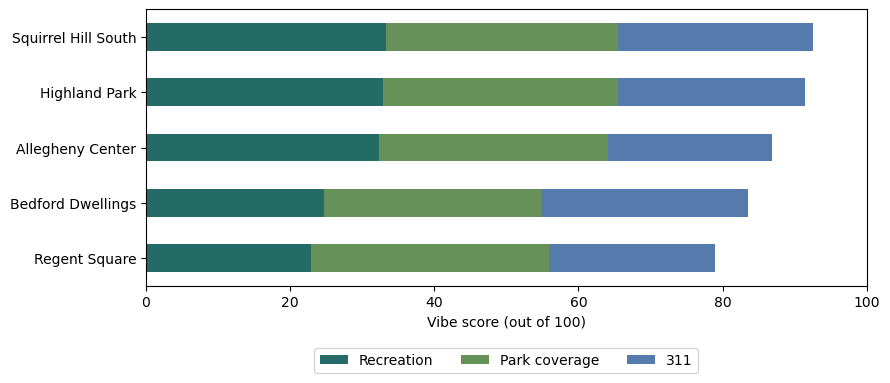

In [18]:
import matplotlib.pyplot as plt

winners = scores[scores["Rank"] == 1]
for _, winner in winners.iterrows():
    print(f"Rank 1: {winner['neighborhood']} ({winner['Vibe score']:.2f}/100)")

if len(winners) == 1 and len(scores) > 1:
    runner_up = scores.iloc[1]
    difference = winners.iloc[0][measures] - runner_up[measures]
    print(f"Largest advantage over {runner_up['neighborhood']}: {difference.idxmax()}")

chart = top.set_index("neighborhood")[measures] / 3
ax = chart.plot.barh(stacked=True, figsize=(9, max(4, len(top) * 0.5)),
                     color=["#246B67", "#66925A", "#547BAB"])
ax.invert_yaxis()
ax.set(xlabel="Vibe score (out of 100)", ylabel="", xlim=(0, 100))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax.figure.tight_layout()
plt.show()

## Conclusion

Our ranking balances three questions: what can people do, how much land is dedicated to parks, and how often are issues reported? Percentiles make the measures comparable, while the choice to weight them equally reflects what our group values. Parks and recreation can favor some of the same neighborhoods, and the 311 rate depends on how people use the service.

### Personal reflections

- **Jack McRae** — My personal favorite is shadyside, which I was suprised didn't even make the top 5. I would also say Squirrel Hill is one of my favorites, which does have the best vibe.  
- **Zach Lovas** — Add a short comparison between the group result and your personal favorite.
- **Vybhav Reddy** — While I don't have a specific favorite neighborhood, Squirrel Hill is one of my favorites so it's nice that it was number one. I am surprised at how much lower it was on the 311 scale compared to the other 2.